# Part I - Correcting the Lag under Harsh Conditions: Forward–Backward Exponential Smoothing

In [4]:
import numpy as np
from matplotlib import pyplot as plt

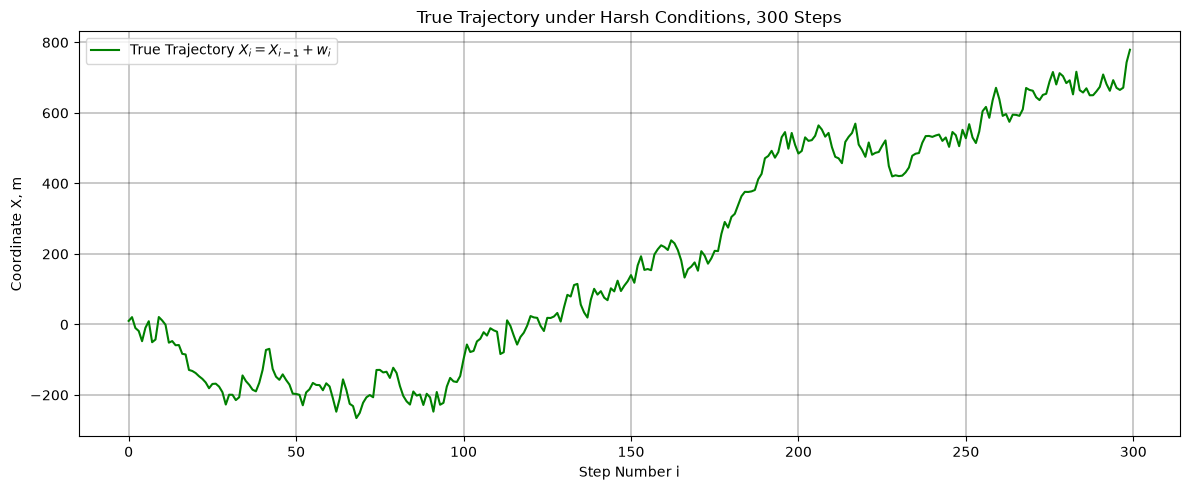

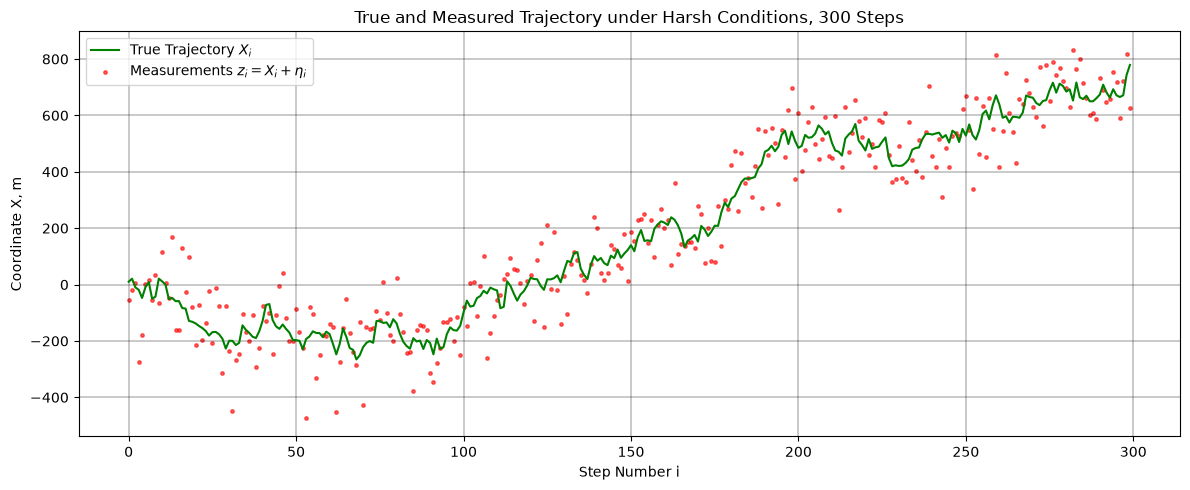

In [5]:
# save generated trajectories so the whole team works on the same data
from pathlib import Path

output_dir = Path("common_files")
output_dir.mkdir(parents=True, exist_ok=True)

# load the trajectories shared within the team
true_trajectory_harsh = np.loadtxt(output_dir / "true_trajectory_harsh.txt")
measured_trajectory_harsh = np.loadtxt(output_dir / "measured_trajectory_harsh.txt")

# recall constants for trajectory modelling from assignment 2 (part II)
SIZE_MIN = 300
INITIAL_COORDINATE_M = 10

VARIANCE_W_HARSH = 28**2
SIGMA_W_HARSH = np.sqrt(VARIANCE_W_HARSH)

VARIANCE_ETA_HARSH = 97**2
SIGMA_ETA_HARSH = np.sqrt(VARIANCE_ETA_HARSH)

# recall a function to generate a true trajectory of a walking panda using the random walk model (from assignment 2 (part II))
def generate_true_trajectory(size, init_coord, sigma):
    traj_points = np.zeros(size)
    traj_points[0] = init_coord

    for i in range(1, size):
        process_noise = np.random.normal(
                        loc=0.0,
                        scale=sigma
                    )
        traj_points[i] = traj_points[i-1] + process_noise

    return traj_points

# recall a function to generate measured trajectory points based on the true trajectory (from assignment 2 (part II))
def generate_measured_trajectory(true_trajectory, sigma_eta):
    measured_trajectory = true_trajectory.copy()
    return measured_trajectory + np.random.normal(0.0, sigma_eta, size=measured_trajectory.size)

# recall a function to plot a true trajectory
def plot_true_trajectory(true_traj, title):
    steps = np.arange(true_traj.size)
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(steps, true_traj, color="green", linewidth=1.5, label="True Trajectory $X_i = X_{i-1} + w_i$")
    ax.set_title(title)
    ax.set_xlabel("Step Number i")
    ax.set_ylabel("Coordinate X, m")
    ax.grid(True, color="black", linewidth=0.3)
    ax.legend(frameon=True)
    fig.tight_layout()
    plt.show()

# recall a function to plot a true trajectory and measured points
def plot_true_vs_measured(true_traj, measured_traj, title, step_size=1):
    steps = np.arange(true_traj.size * step_size, step = step_size)
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(steps, true_traj, color="green", linewidth=1.5, label="True Trajectory $X_i$")
    ax.scatter(steps, measured_traj, color="red", s=6, alpha=0.6, label="Measurements $z_i = X_i + \\eta_i$")
    ax.set_title(title)
    ax.set_xlabel("Step Number i")
    ax.set_ylabel("Coordinate X, m")
    ax.grid(True, color="black", linewidth=0.3)
    ax.legend(frameon=True)
    fig.tight_layout()
    plt.show()

# call the functions above to get trajectories and plot them
# true_trajectory_harsh = generate_true_trajectory(SIZE_MIN, INITIAL_COORDINATE_M, SIGMA_W_HARSH)
plot_true_trajectory(true_trajectory_harsh, "True Trajectory under Harsh Conditions, 300 Steps")

# measured_trajectory_harsh = generate_measured_trajectory(true_trajectory_harsh, SIGMA_ETA_HARSH)
plot_true_vs_measured(true_trajectory_harsh, measured_trajectory_harsh, "True and Measured Trajectory under Harsh Conditions, 300 Steps")

In [6]:
# save generated trajectories so the whole team works on the same data
from pathlib import Path

output_dir = Path("common_files")
output_dir.mkdir(parents=True, exist_ok=True)

np.savetxt(output_dir / "true_trajectory_harsh.txt", true_trajectory_harsh)
np.savetxt(output_dir / "measured_trajectory_harsh.txt", measured_trajectory_harsh)

# load the trajectories shared within the team
# true_trajectory_harsh = np.loadtxt(output_dir / "true_trajectory_harsh.txt")
# measured_trajectory_harsh = np.loadtxt(output_dir / "measured_trajectory_harsh.txt")

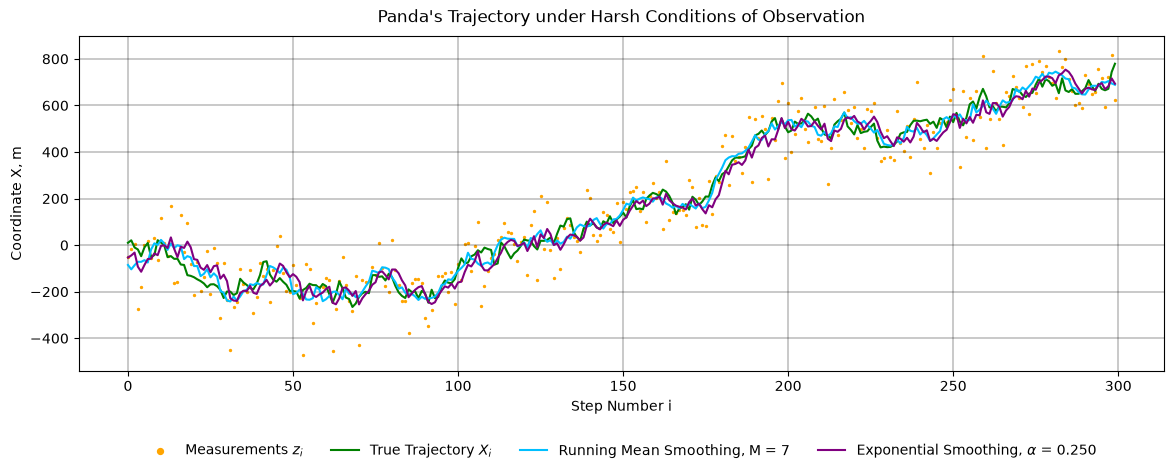

In [7]:
# recall forward exponential smoothing
def exponential_smoothing(measurements, alpha):
    smoothed_points = np.zeros(measurements.size)
    smoothed_points[0] = measurements[0]
    
    for i in range(1, measurements.size):
        smoothed_points[i] = smoothed_points[i - 1] + alpha * (measurements[i] - smoothed_points[i-1])
    
    return smoothed_points

# recall the function to find the optimal smoothing coefficient for exponential smoothing
def get_optimal_alpha(variance_w, variance_eta):
    chi = variance_w / variance_eta
    return (-chi + np.sqrt(chi**2 + 4 * chi)) / 2

# recall the optimal smoothing coefficient under harsh conditions
alpha_optimal_harsh = get_optimal_alpha(VARIANCE_W_HARSH, VARIANCE_ETA_HARSH)

# recall the window size M that ensures the equality of a running-mean error and an exponential-smoothing error
m_rounded = round((2 - alpha_optimal_harsh) / alpha_optimal_harsh)

# apply running-mean smoothing to the points measured under harsh conditions
def running_mean_smoothing(measurements, m):
    n = measurements.size
    running_mean_points = np.full(n, np.nan)
    left = (m - 1) // 2
    right = m - left
    for i in range(n):
        start = max(0, i - left)
        stop = min(n, i + right)
        running_mean_points[i] = np.mean(measurements[start:stop])
    
    return running_mean_points

running_mean_traj_points = running_mean_smoothing(measured_trajectory_harsh, m_rounded)

# apply exponential smoothing to the points measured under harsh conditions
f_exp_smoothed_points = exponential_smoothing(measured_trajectory_harsh, alpha_optimal_harsh)

# plot the panda’s true trajectory, measurements, and both the running and exponential means
fig, ax = plt.subplots(figsize=(12, 5))
steps = np.arange(true_trajectory_harsh.size)
ax.scatter(steps, measured_trajectory_harsh, color="orange", s=2, label="Measurements $z_i$")
ax.plot(steps, true_trajectory_harsh, color="green", linewidth=1.5, label="True Trajectory $X_i$")
ax.plot(steps, running_mean_traj_points, color="deepskyblue", linewidth=1.5, label=f"Running Mean Smoothing, M = {m_rounded}")
ax.plot(steps, f_exp_smoothed_points, color="purple", linewidth=1.5, label=f"Exponential Smoothing, $\\alpha$ = {alpha_optimal_harsh:.3f}")
ax.set_title("Panda's Trajectory under Harsh Conditions of Observation", pad=10)
ax.set_xlabel("Step Number i")
ax.set_ylabel("Coordinate X, m")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(
        frameon=False, 
        markerscale=3, 
        ncol=4,  
        loc="lower center",
        bbox_to_anchor=(0.5, -0.3)
    )
fig.tight_layout()
plt.show()
    

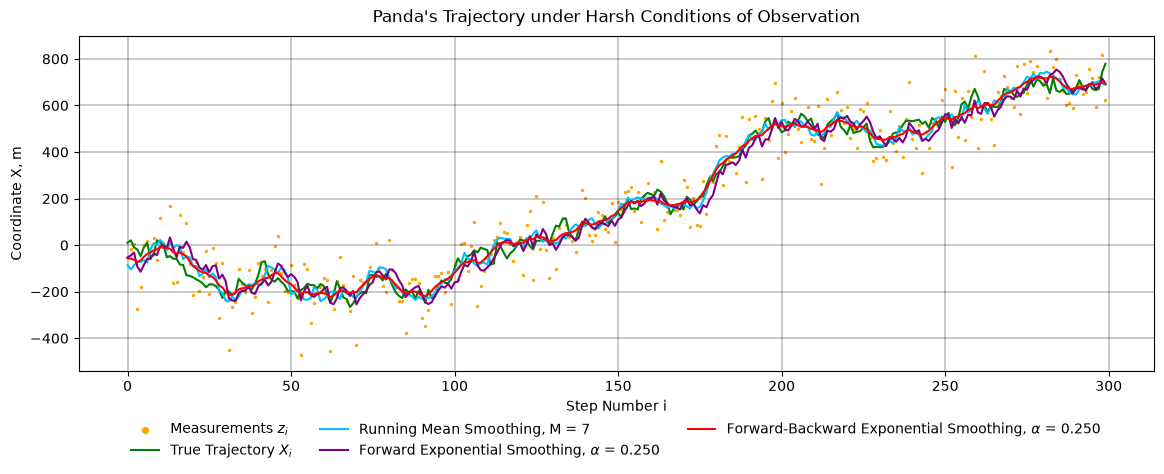

In [8]:
# perform backward exponential smoothing on the forward exponential smoothing
def run_backward_exp_smoothing(f_values, alpha):
    b_values = np.zeros(f_values.size)
    b_values[b_values.size - 1] = f_values[f_values.size - 1]
    for i in range(b_values.size - 2, -1, -1):
        b_values[i] = b_values[i + 1] + alpha * (f_values[i] - b_values[i + 1])
    return b_values

b_exp_smoothed_points = run_backward_exp_smoothing(f_exp_smoothed_points, alpha_optimal_harsh)

# plot the panda’s true trajectory, measurements, and both the running and exponential means, both after forward and forward-backward smoothing
fig, ax = plt.subplots(figsize=(12, 5))
steps = np.arange(true_trajectory_harsh.size)
ax.scatter(steps, measured_trajectory_harsh, color="orange", s=2, label="Measurements $z_i$")
ax.plot(steps, true_trajectory_harsh, color="green", linewidth=1.5, label="True Trajectory $X_i$")
ax.plot(steps, running_mean_traj_points, color="deepskyblue", linewidth=1.5, label=f"Running Mean Smoothing, M = {m_rounded}")
ax.plot(steps, f_exp_smoothed_points, color="purple", linewidth=1.5, label=f"Forward Exponential Smoothing, $\\alpha$ = {alpha_optimal_harsh:.3f}")
ax.plot(steps, b_exp_smoothed_points, color="red", linewidth=1.5, label=f"Forward-Backward Exponential Smoothing, $\\alpha$ = {alpha_optimal_harsh:.3f}")
ax.set_title("Panda's Trajectory under Harsh Conditions of Observation", pad=10)
ax.set_xlabel("Step Number i")
ax.set_ylabel("Coordinate X, m")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(
        frameon=False, 
        markerscale=3, 
        ncol=3,  
        loc="lower center",
        bbox_to_anchor=(0.5, -0.3)
    )
fig.tight_layout()
plt.show()
    

In [9]:
# find the indicatiors of smoothing performance
def find_smoothing_indicators(measured, estimated):
    deviation = np.sum((measured - estimated)**2)
    variability = np.sum((estimated[2:] - 2*estimated[1:-1] + estimated[:-2])**2)

    return deviation, variability

run_mean_dev, run_mean_var = find_smoothing_indicators(measured_trajectory_harsh, running_mean_traj_points)
print(f"Running mean smoothing: deviation indicator = {run_mean_dev:.3f}, variability indicator = {run_mean_var:.3f}")

b_exp_smooth_dev, b_exp_smooth_var = find_smoothing_indicators(measured_trajectory_harsh, b_exp_smoothed_points)
print(f"Forward-backward exponential smoothing: deviation indicator = {b_exp_smooth_dev:.3f}, variability indicator = {b_exp_smooth_var:.3f}")

Running mean smoothing: deviation indicator = 2454133.138, variability indicator = 251999.891
Forward-backward exponential smoothing: deviation indicator = 2314340.165, variability indicator = 16035.856


# Part II — When running mean shines, and when it stumbles

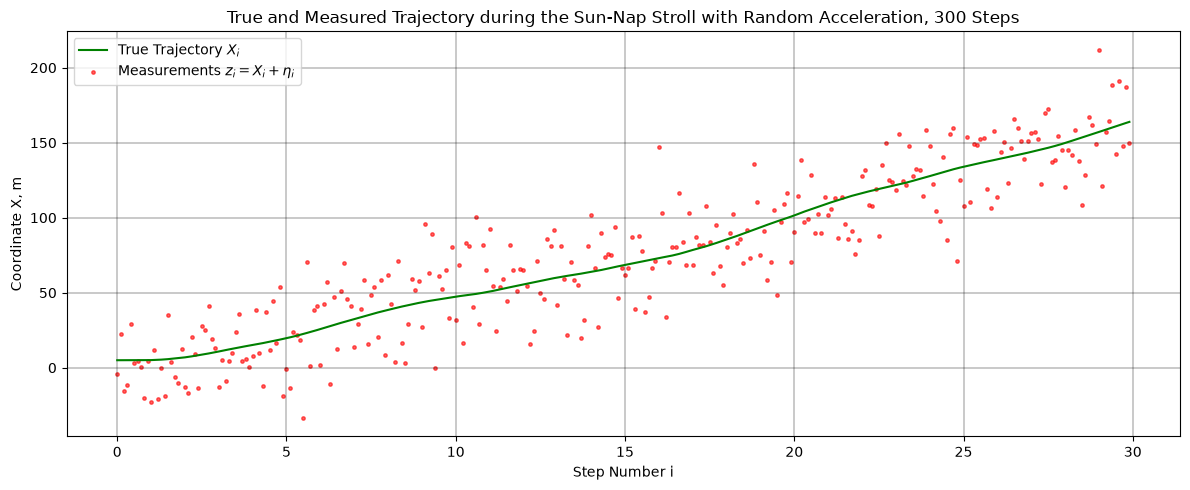

In [ ]:
# panda's true trajectory during the sun-nap stroll
T = 0.1
VARIANCE_A = 10
INITIAL_COORDINATE_SUN_NAP_M = 5
INITIAL_VELOCITY_SUN_NAP_M_S = 0
VARIANCE_ETA_SUN_NAP = 500

n = measured_trajectory_harsh.size
true_trajectory_sun_nap = np.zeros(n)
velocity_sun_nap = np.zeros(n)
acceleration_sun_nap = np.random.normal(0, np.sqrt(VARIANCE_A), n - 1)

true_trajectory_sun_nap[0] = INITIAL_COORDINATE_SUN_NAP_M
velocity_sun_nap[0] = INITIAL_VELOCITY_SUN_NAP_M_S

# generate the true trajectory during the sun-nap stroll
for i in range(1, n):
    true_trajectory_sun_nap[i] = (
        true_trajectory_sun_nap[i - 1]
        + velocity_sun_nap[i - 1] * T
        + 0.5 * acceleration_sun_nap[i - 1] * T**2
    )
    velocity_sun_nap[i] = velocity_sun_nap[i - 1] + acceleration_sun_nap[i - 1] * T

# generate the measured trajectory during the sun-nap stroll
measured_trajectory_sun_nap = generate_measured_trajectory(true_trajectory_sun_nap, np.sqrt(VARIANCE_ETA_SUN_NAP))

# plot the panda’s true trajectory and measured points during the sun-nap stroll
plot_true_vs_measured(true_trajectory_sun_nap, measured_trajectory_sun_nap, "True and Measured Trajectory during the Sun-Nap Stroll with Random Acceleration, 300 Steps", step_size=T)

*Since the trajectory closely resembles a line and the measurement errors are significant, we shall opt for a greater window size*

Totally, we have 300 points. 


It seems reasonable if we choose our first window size to be of the same decimal order, and start with M = 100

In [ ]:
"""
np.savetxt(output_dir / "true_trajectory_sun_nap.txt", true_trajectory_sun_nap)
np.savetxt(output_dir / "measured_trajectory_sun_nap.txt", measured_trajectory_sun_nap)"""

true_trajectory_sun_nap = np.loadtxt(output_dir / "true_trajectory_sun_nap.txt")
measured_trajectory_sun_nap = np.loadtxt(output_dir / "measured_trajectory_sun_nap.txt")

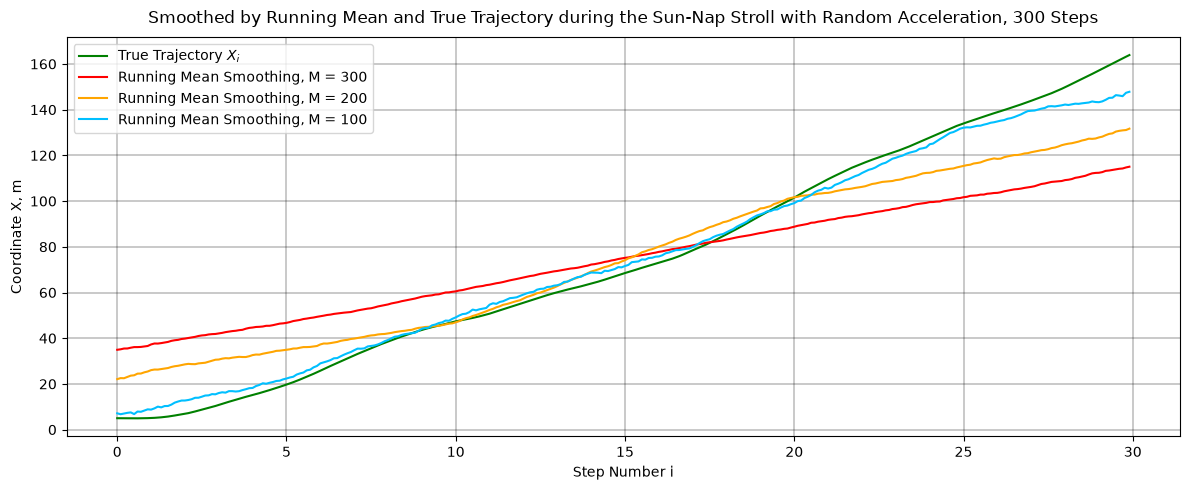

In [17]:
# find the optimal window size M for running-mean smoothing during the sun-nap stroll

m_values = [300, 200, 100]
colors = ["red", "orange", "deepskyblue"]

steps = np.arange(n * T, step = T)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(steps, true_trajectory_sun_nap, color="green", linewidth=1.5, label="True Trajectory $X_i$")
# ax.scatter(steps, measured_trajectory_sun_nap, color="orange", s=2, label="Measurements $z_i$")
for i in range(len(m_values)):
    ax.plot(
        steps, 
        running_mean_smoothing(measured_trajectory_sun_nap, m_values[i]), 
        color=colors[i], 
        linewidth=1.5,
        label=f"Running Mean Smoothing, M = {m_values[i]}"
    )
ax.set_title("Smoothed by Running Mean and True Trajectory during the Sun-Nap Stroll with Random Acceleration, 300 Steps", pad=10)
ax.set_xlabel("Step Number i")
ax.set_ylabel("Coordinate X, m")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=True)
fig.tight_layout()
plt.show()

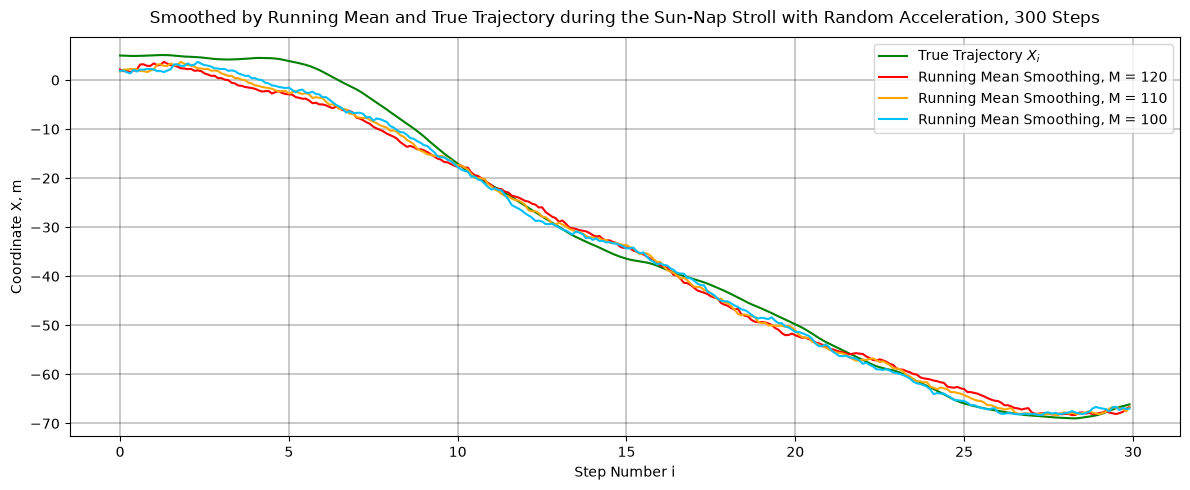

In [78]:
m_values = [120, 110, 100,]
colors = ["red", "orange", "deepskyblue",]

steps = np.arange(n * T, step = T)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(steps, true_trajectory_sun_nap, color="green", linewidth=1.5, label="True Trajectory $X_i$")
# ax.scatter(steps, measured_trajectory_sun_nap, color="orange", s=2, label="Measurements $z_i$")
for i in range(len(m_values)):
    ax.plot(
        steps, 
        running_mean_smoothing(measured_trajectory_sun_nap, m_values[i]), 
        color=colors[i], 
        linewidth=1.5,
        label=f"Running Mean Smoothing, M = {m_values[i]}"
    )
ax.set_title("Smoothed by Running Mean and True Trajectory during the Sun-Nap Stroll with Random Acceleration, 300 Steps", pad=10)
ax.set_xlabel("Step Number i")
ax.set_ylabel("Coordinate X, m")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=True)
fig.tight_layout()

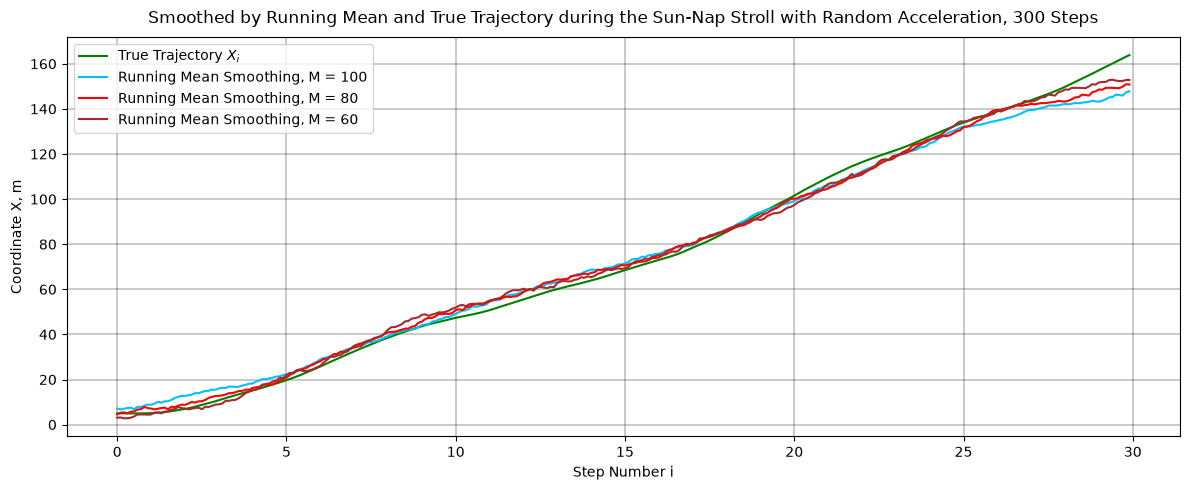

In [29]:
m_values = [100, 80, 60,]
colors = ["deepskyblue", "red", "brown",]

steps = np.arange(n * T, step = T)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(steps, true_trajectory_sun_nap, color="green", linewidth=1.5, label="True Trajectory $X_i$")
# ax.scatter(steps, measured_trajectory_sun_nap, color="orange", s=2, label="Measurements $z_i$")
for i in range(len(m_values)):
    ax.plot(
        steps, 
        running_mean_smoothing(measured_trajectory_sun_nap, m_values[i]), 
        color=colors[i], 
        linewidth=1.5,
        label=f"Running Mean Smoothing, M = {m_values[i]}"
    )
ax.set_title("Smoothed by Running Mean and True Trajectory during the Sun-Nap Stroll with Random Acceleration, 300 Steps", pad=10)
ax.set_xlabel("Step Number i")
ax.set_ylabel("Coordinate X, m")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=True)
fig.tight_layout()

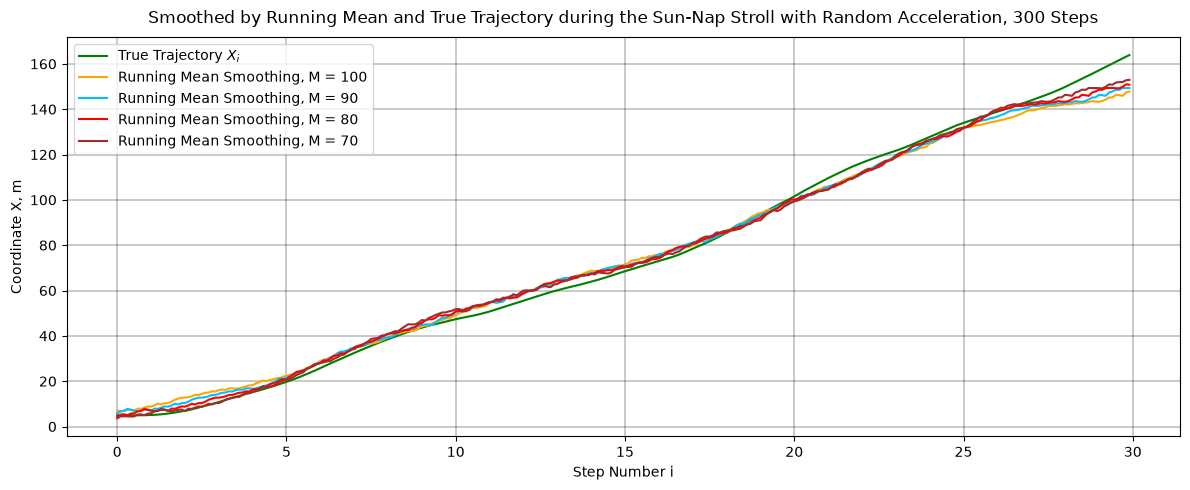

In [31]:
m_values = [100, 90, 80, 70]
colors = ["orange", "deepskyblue", "red", "brown",]

steps = np.arange(n * T, step = T)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(steps, true_trajectory_sun_nap, color="green", linewidth=1.5, label="True Trajectory $X_i$")
# ax.scatter(steps, measured_trajectory_sun_nap, color="orange", s=2, label="Measurements $z_i$")
for i in range(len(m_values)):
    ax.plot(
        steps, 
        running_mean_smoothing(measured_trajectory_sun_nap, m_values[i]), 
        color=colors[i], 
        linewidth=1.5,
        label=f"Running Mean Smoothing, M = {m_values[i]}"
    )
ax.set_title("Smoothed by Running Mean and True Trajectory during the Sun-Nap Stroll with Random Acceleration, 300 Steps", pad=10)
ax.set_xlabel("Step Number i")
ax.set_ylabel("Coordinate X, m")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=True)
fig.tight_layout()

We also have to decide on the optimal coefficient for exponential smoothing emperically. Since the measurement errors are large, we have to choose a comparatively small value of $$\alpha$$, closer to zero than to one.

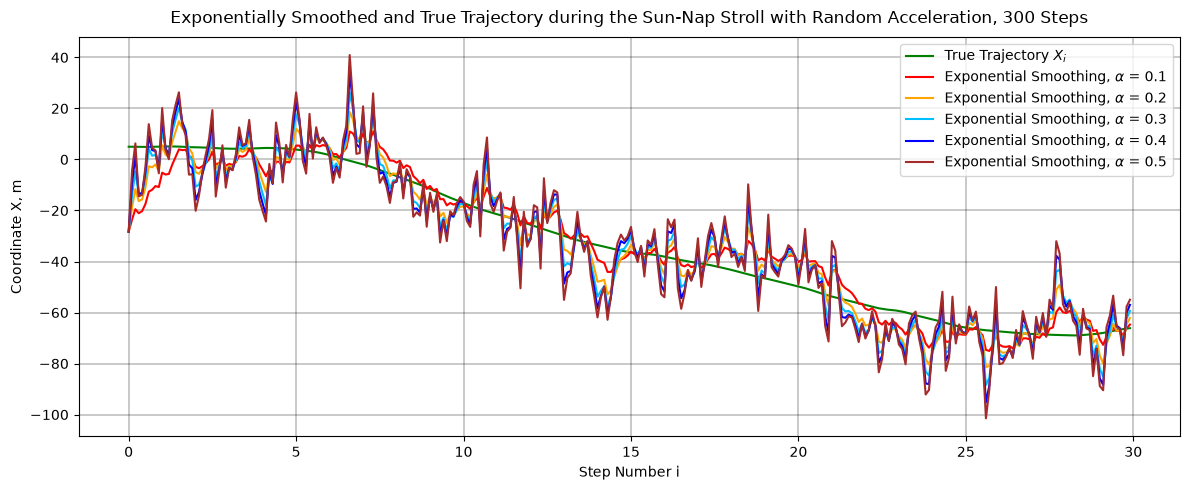

In [79]:
# find the optimal coefficient for exponential smoothing during the sun-nap stroll
alpha_values = [0.1, 0.2, 0.3, 0.4, 0.5]
colors = ["red", "orange", "deepskyblue", "blue", "brown"]

steps = np.arange(n * T, step = T)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(steps, true_trajectory_sun_nap, color="green", linewidth=1.5, label="True Trajectory $X_i$")
# ax.scatter(steps, measured_trajectory_sun_nap, color="orange", s=2, label="Measurements $z_i$")
for i in range(len(alpha_values)):
    ax.plot(
        steps, 
        exponential_smoothing(measured_trajectory_sun_nap, alpha_values[i]), 
        color=colors[i], 
        linewidth=1.5,
        label=f"Exponential Smoothing, $\\alpha$ = {alpha_values[i]}"
    )
ax.set_title("Exponentially Smoothed and True Trajectory during the Sun-Nap Stroll with Random Acceleration, 300 Steps", pad=10)
ax.set_xlabel("Step Number i")
ax.set_ylabel("Coordinate X, m")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=True)
fig.tight_layout()

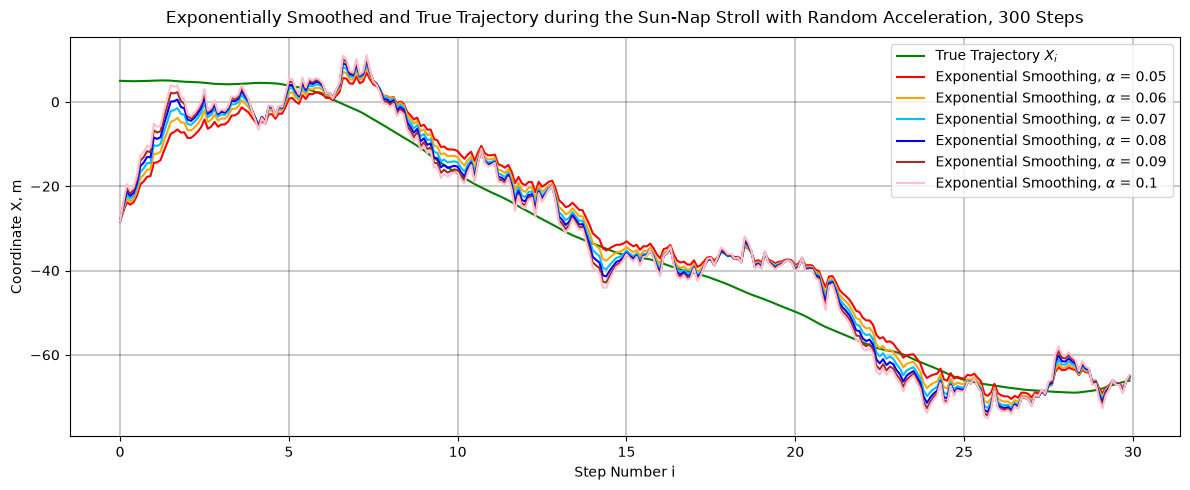

In [80]:
# find the optimal coefficient for exponential smoothing during the sun-nap stroll
alpha_values = [0.05, 0.06, 0.07, 0.08, 0.09, 0.1]
colors = ["red", "orange", "deepskyblue", "blue", "brown", "pink"]

steps = np.arange(n * T, step = T)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(steps, true_trajectory_sun_nap, color="green", linewidth=1.5, label="True Trajectory $X_i$")
# ax.scatter(steps, measured_trajectory_sun_nap, color="orange", s=2, label="Measurements $z_i$")
for i in range(len(alpha_values)):
    ax.plot(
        steps, 
        exponential_smoothing(measured_trajectory_sun_nap, alpha_values[i]), 
        color=colors[i], 
        linewidth=1.5,
        label=f"Exponential Smoothing, $\\alpha$ = {alpha_values[i]}"
    )
ax.set_title("Exponentially Smoothed and True Trajectory during the Sun-Nap Stroll with Random Acceleration, 300 Steps", pad=10)
ax.set_xlabel("Step Number i")
ax.set_ylabel("Coordinate X, m")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=True)
fig.tight_layout()

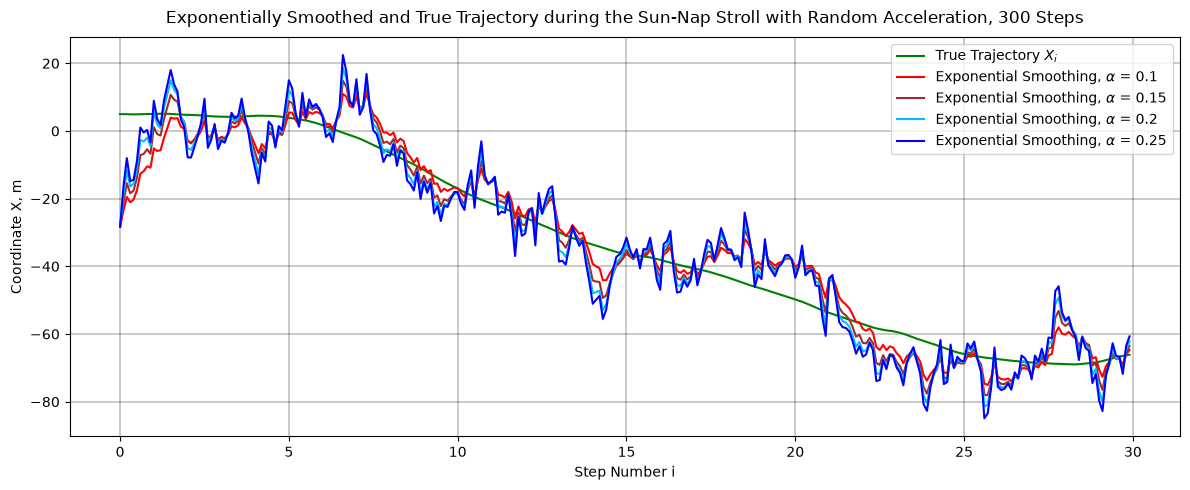

In [82]:
# find the optimal coefficient for exponential smoothing during the sun-nap stroll
alpha_values = [0.1, 0.15, 0.2, 0.25]
colors = ["red", "brown", "deepskyblue", "blue"]

steps = np.arange(n * T, step = T)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(steps, true_trajectory_sun_nap, color="green", linewidth=1.5, label="True Trajectory $X_i$")
# ax.scatter(steps, measured_trajectory_sun_nap, color="orange", s=2, label="Measurements $z_i$")
for i in range(len(alpha_values)):
    ax.plot(
        steps, 
        exponential_smoothing(measured_trajectory_sun_nap, alpha_values[i]), 
        color=colors[i], 
        linewidth=1.5,
        label=f"Exponential Smoothing, $\\alpha$ = {alpha_values[i]}"
    )
ax.set_title("Exponentially Smoothed and True Trajectory during the Sun-Nap Stroll with Random Acceleration, 300 Steps", pad=10)
ax.set_xlabel("Step Number i")
ax.set_ylabel("Coordinate X, m")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=True)
fig.tight_layout()

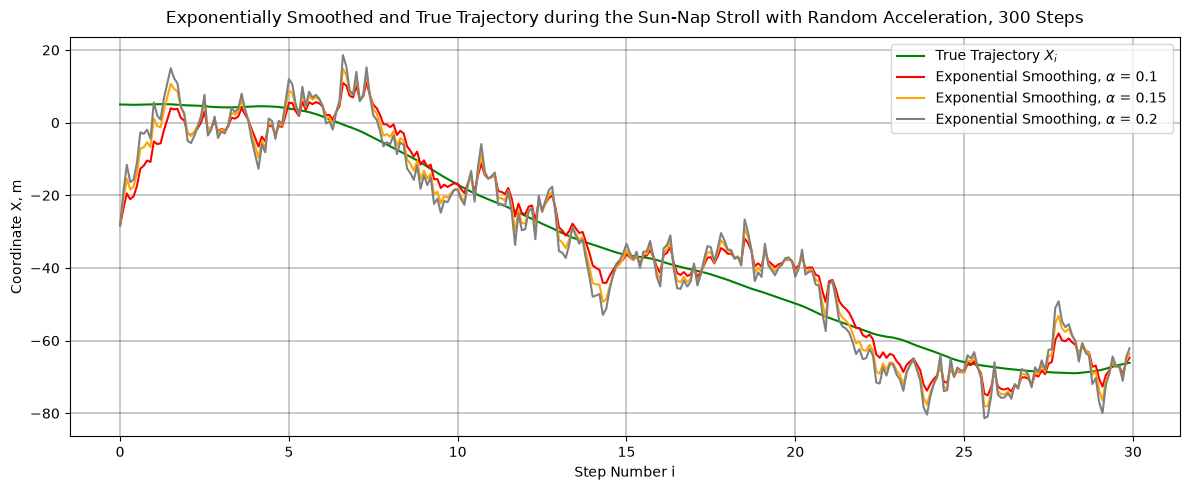

In [83]:
# find the optimal coefficient for exponential smoothing during the sun-nap stroll
alpha_values = [0.1, 0.15, 0.2]
colors = ["red", "orange", "grey"]

steps = np.arange(n * T, step = T)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(steps, true_trajectory_sun_nap, color="green", linewidth=1.5, label="True Trajectory $X_i$")
# ax.scatter(steps, measured_trajectory_sun_nap, color="orange", s=2, label="Measurements $z_i$")
for i in range(len(alpha_values)):
    ax.plot(
        steps, 
        exponential_smoothing(measured_trajectory_sun_nap, alpha_values[i]), 
        color=colors[i], 
        linewidth=1.5,
        label=f"Exponential Smoothing, $\\alpha$ = {alpha_values[i]}"
    )
ax.set_title("Exponentially Smoothed and True Trajectory during the Sun-Nap Stroll with Random Acceleration, 300 Steps", pad=10)
ax.set_xlabel("Step Number i")
ax.set_ylabel("Coordinate X, m")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=True)
fig.tight_layout()

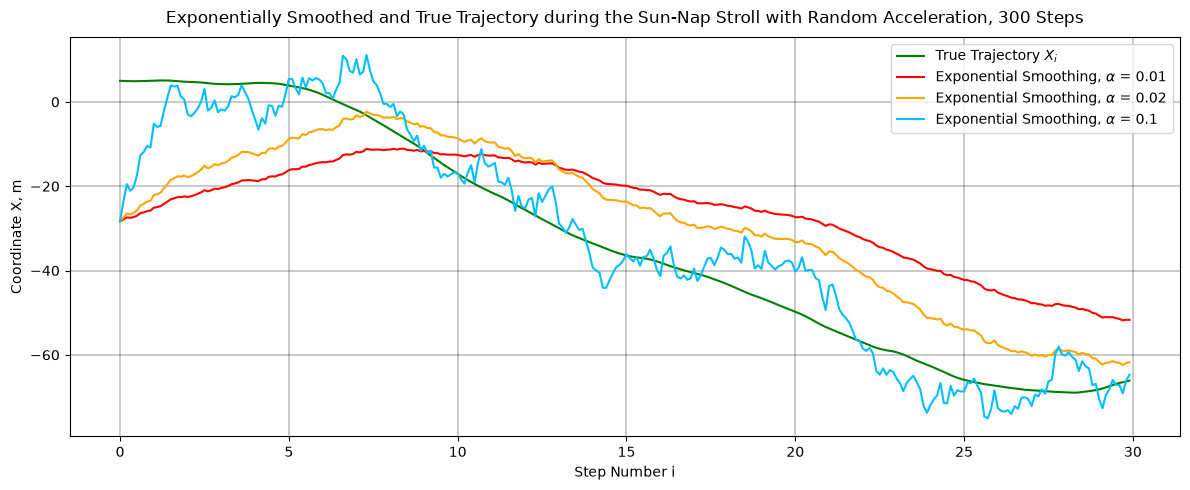

In [84]:
# find the optimal coefficient for exponential smoothing during the sun-nap stroll
alpha_values = [0.01, 0.02, 0.1, ]
colors = ["red", "orange", "deepskyblue", ]

steps = np.arange(n * T, step = T)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(steps, true_trajectory_sun_nap, color="green", linewidth=1.5, label="True Trajectory $X_i$")
# ax.scatter(steps, measured_trajectory_sun_nap, color="orange", s=2, label="Measurements $z_i$")
for i in range(len(alpha_values)):
    ax.plot(
        steps, 
        exponential_smoothing(measured_trajectory_sun_nap, alpha_values[i]), 
        color=colors[i], 
        linewidth=1.5,
        label=f"Exponential Smoothing, $\\alpha$ = {alpha_values[i]}"
    )
ax.set_title("Exponentially Smoothed and True Trajectory during the Sun-Nap Stroll with Random Acceleration, 300 Steps", pad=10)
ax.set_xlabel("Step Number i")
ax.set_ylabel("Coordinate X, m")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=True)
fig.tight_layout()

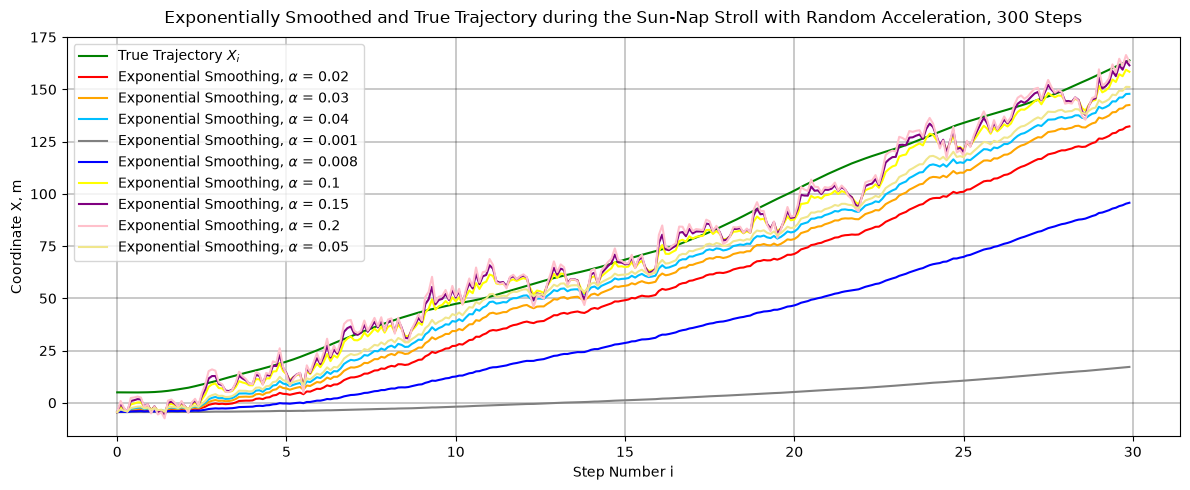

In [15]:
# find the optimal coefficient for exponential smoothing during the sun-nap stroll
alpha_values = [0.02, 0.03, 0.04, 0.001, 0.008, 0.1,  0.15, 0.2, 0.05]
colors = ["red", "orange", "deepskyblue", "grey", "blue", "yellow", "purple", "pink", "khaki"]

steps = np.arange(n * T, step = T)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(steps, true_trajectory_sun_nap, color="green", linewidth=1.5, label="True Trajectory $X_i$")
# ax.scatter(steps, measured_trajectory_sun_nap, color="orange", s=2, label="Measurements $z_i$")
for i in range(len(alpha_values)):
    ax.plot(
        steps, 
        exponential_smoothing(measured_trajectory_sun_nap, alpha_values[i]), 
        color=colors[i], 
        linewidth=1.5,
        label=f"Exponential Smoothing, $\\alpha$ = {alpha_values[i]}"
    )
ax.set_title("Exponentially Smoothed and True Trajectory during the Sun-Nap Stroll with Random Acceleration, 300 Steps", pad=10)
ax.set_xlabel("Step Number i")
ax.set_ylabel("Coordinate X, m")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=True)
fig.tight_layout()

We choose optimal alpha = 0,1 for our trajectory 

In [13]:
# select the more effective smoothing method based on deviation and variability indicator
run_mean_dev, run_mean_var = find_smoothing_indicators(measured_trajectory_harsh, running_mean_smoothing(measured_trajectory_sun_nap))
print(f"Running mean smoothing: deviation indicator = {run_mean_dev:.3f}, variability indicator = {run_mean_var:.3f}")

b_exp_smooth_dev, b_exp_smooth_var = find_smoothing_indicators(measured_trajectory_harsh, b_exp_smoothed_points)
print(f"Forward-backward exponential smoothing: deviation indicator = {b_exp_smooth_dev:.3f}, variability indicator = {b_exp_smooth_var:.3f}")

TypeError: running_mean_smoothing() missing 1 required positional argument: 'm'